# Лабораторна робота 3. Нейронні мережі. Навчання мережі
Бібліотека: **TensorFlow / Keras**, середовище: Google Colab. Задача: розпізнавання рукописних цифр (MNIST).

## 1. Підключення бібліотек

In [2]:
# Підключаємо бібліотеки
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
print('Версія TensorFlow:', tf.__version__)
print('Бібліотеки підключено успішно!')

Версія TensorFlow: 2.21.0
Бібліотеки підключено успішно!


## 2. Завантаження набору даних MNIST

In [3]:
# Завантажуємо набір даних MNIST
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
print('Навчальних зображень:', x_train.shape[0])
print('Тестових зображень:  ', x_test.shape[0])
print('Розмір зображення:   ', x_train.shape[1], 'x', x_train.shape[2], 'пікселів')

Навчальних зображень: 60000
Тестових зображень:   10000
Розмір зображення:    28 x 28 пікселів


## 3. Приклади з набору даних

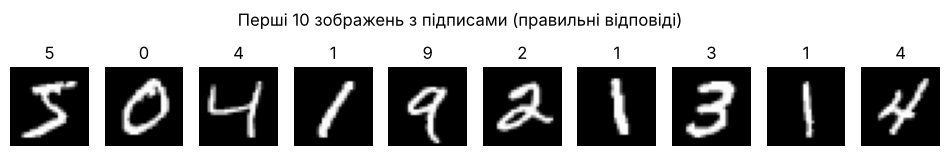

In [4]:
# Показуємо перші 10 прикладів
plt.figure(figsize=(12, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(str(y_train[i]))
    plt.axis('off')
plt.suptitle('Перші 10 зображень з підписами (правильні відповіді)')
plt.show()

## 4. Нормалізація даних
Пікселі мають значення 0..255; ділимо на 255, щоб отримати діапазон [0, 1].

In [5]:
# Нормалізуємо пікселі: з діапазону [0, 255] до [0, 1]
x_train = x_train / 255.0
x_test  = x_test  / 255.0
print('Готово! Діапазон значень тепер від', x_train.min(), 'до', x_train.max())

Готово! Діапазон значень тепер від 0.0 до 1.0


## 5. Побудова нейронної мережі
Три типи шарів: вхідний (Flatten), прихований (Dense 128, ReLU), вихідний (Dense 10, softmax).

In [6]:
# Будуємо модель нейронної мережі
model = keras.Sequential([
    # Вхідний шар: розгортаємо зображення 28x28 у вектор з 784 чисел
    keras.layers.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    # Прихований шар: 128 нейронів, функція активації ReLU
    keras.layers.Dense(128, activation='relu'),
    # Вихідний шар: 10 нейронів (по одному на кожну цифру 0-9), softmax -> ймовірності
    keras.layers.Dense(10, activation='softmax')
])
# Виводимо структуру мережі
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Навчання мережі

In [7]:
# Налаштовуємо процес навчання
model.compile(
    optimizer='adam',                         # Алгоритм оновлення ваг
    loss='sparse_categorical_crossentropy',   # Функція помилки
    metrics=['accuracy']                      # Відстежуємо точність
)
print('Модель готова до навчання!')

Модель готова до навчання!


In [8]:
# Навчаємо модель
history = model.fit(
    x_train, y_train,
    epochs=5,             # Кількість проходів по всіх даних
    batch_size=32,        # Скільки прикладів за один крок
    validation_split=0.1  # 10% навчальних даних — для перевірки
)
print('Навчання завершено!')

Epoch 1/5


   1/1688 ━━━━━━━━━━━━━━━━━━━━ 15:27 550ms/step - accuracy: 0.1250 - loss: 2.3191

  22/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.4858 - loss: 1.6904     

  44/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6300 - loss: 1.2819

  65/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6933 - loss: 1.0766

...

1646/1688 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9857 - loss: 0.0477

1667/1688 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9857 - loss: 0.0478

1688/1688 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9857 - loss: 0.0478

1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9857 - loss: 0.0478 - val_accuracy: 0.9757 - val_loss: 0.0808


Навчання завершено!


## 7. Оцінка точності на тестових даних

In [9]:
# Оцінюємо модель на тестовій вибірці (дані, яких мережа не бачила)
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print(f'Точність на тестових даних: {test_accuracy * 100:.2f}%')
print(f'Помилка (loss):             {test_loss:.4f}')

  1/313 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 1.0000 - loss: 0.0142

 33/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9782 - loss: 0.0805 

 63/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9707 - loss: 0.1115

107/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9702 - loss: 0.1072

154/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9700 - loss: 0.1067

191/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9709 - loss: 0.1012

239/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9748 - loss: 0.0860

286/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9766 - loss: 0.0783

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9766 - loss: 0.0781


Точність на тестових даних: 97.66%
Помилка (loss):             0.0781


## 8. Графік навчання

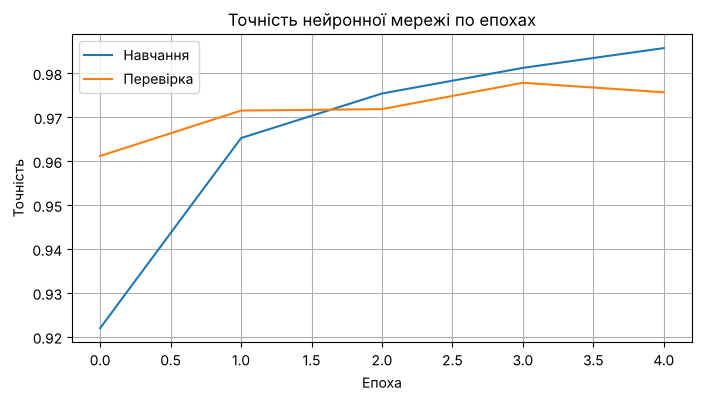

In [10]:
# Графік точності під час навчання
plt.figure(figsize=(8, 4))
plt.plot(history.history['accuracy'],     label='Навчання')
plt.plot(history.history['val_accuracy'], label='Перевірка')
plt.title('Точність нейронної мережі по епохах')
plt.xlabel('Епоха')
plt.ylabel('Точність')
plt.legend()
plt.grid(True)
plt.show()

## 9. Перевірка на конкретних прикладах

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


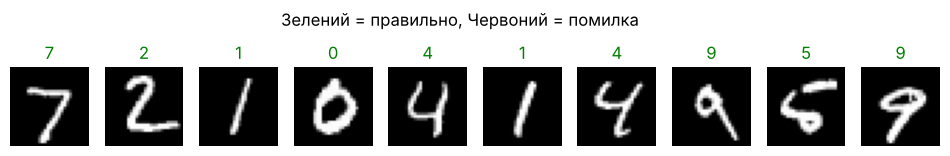

In [11]:
# Прогнози для перших 10 тестових зображень
predictions = model.predict(x_test[:10])

plt.figure(figsize=(12, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    predicted = np.argmax(predictions[i])   # Клас з найбільшою ймовірністю
    correct = y_test[i]
    color = 'green' if predicted == correct else 'red'
    plt.title(str(predicted), color=color)
    plt.axis('off')
plt.suptitle('Зелений = правильно, Червоний = помилка')
plt.show()